# Notebook 03 — Champion Model and Monitoring Baselines

**Project:** Design and Evaluation of a Governed Multi-Signal Drift-Aware Intervention Policy under Delayed Labels: A Google Cloud MLOps Prototype 

**Author:** Sahar Imani  
**Notebook:** 3 of 5

This notebook trains the champion model on the 2013 data and builds the baselines that the monitoring in Notebook 04 compares against. The 2014–2016 simulation stream is only scored here. It is not used for fitting or for setting any reference distribution.

## 1. Loading Processed Data 

In [1]:
# Libraries used in this notebook
import os
import json
import joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss)

In [2]:
# Artefacts saved by Notebook 02
historical_path = "../data/processed/historical_2013_clean.parquet"
simulation_path = "../data/processed/simulation_2014_2016_clean.parquet"

features_path = "../data/processed/final_feature_cols.csv"
categorical_path = "../data/processed/categorical_feature_cols.csv"
median_path = "../data/processed/historical_imputation_medians.csv"
cap_path = "../data/processed/historical_capping_limits.csv"
split_summary_path = "../data/processed/split_summary.csv"

In [3]:
# Load the processed chronological splits
historical_df = pd.read_parquet(historical_path)
simulation_df = pd.read_parquet(simulation_path)

# Load metadata
final_feature_cols = pd.read_csv(features_path)["feature"].tolist()
categorical_feature_cols = pd.read_csv(categorical_path)["categorical_feature"].tolist()
historical_medians = pd.read_csv(median_path, index_col=0).squeeze("columns")
cap_limits = pd.read_csv(cap_path, index_col=0).squeeze("columns")
split_summary = pd.read_csv(split_summary_path)

print("Historical dataset shape:", historical_df.shape)
print("Simulation dataset shape:", simulation_df.shape)
print("Number of final features:", len(final_feature_cols))
print("Categorical features:", categorical_feature_cols)

Historical dataset shape: (134814, 73)
Simulation dataset shape: (1041560, 73)
Number of final features: 69
Categorical features: ['home_ownership', 'verification_status', 'purpose']


In [4]:
# Review the chronological split summary from Notebook 02
display(split_summary)

,split,rows,start_date,end_date,bad_loan_rate
0,historical_2013,134814,2013-01-01,2013-12-01,0.1560
1,simulation_2014_2016,1041560,2014-01-01,2016-12-01,0.1925


In [5]:
# Both periods must carry the same features
missing_historical_features = sorted(set(final_feature_cols) - set(historical_df.columns))
missing_simulation_features = sorted(set(final_feature_cols) - set(simulation_df.columns))

print("Missing features in historical dataset:", len(missing_historical_features))
print("Missing features in simulation dataset:", len(missing_simulation_features))

if len(missing_historical_features) > 0:
    print(missing_historical_features)

if len(missing_simulation_features) > 0:
    print(missing_simulation_features)

Missing features in historical dataset: 0
Missing features in simulation dataset: 0


In [6]:
# Confirm that the feature matrices are still complete after loading
historical_feature_nans = historical_df[final_feature_cols].isna().sum().sum()
simulation_feature_nans = simulation_df[final_feature_cols].isna().sum().sum()

print("Historical feature NaNs:", historical_feature_nans)
print("Simulation feature NaNs:", simulation_feature_nans)

Historical feature NaNs: 0
Simulation feature NaNs: 0


## 2. Preparing Features and Target Variables

Features, target and time columns are separated for both periods. The time columns are kept aside rather than dropped, since the monthly replay in Notebook 04 depends on them.

In [7]:
# Target and time columns
target_col = "target_bad_loan"
time_cols = ["issue_d", "issue_year", "issue_month"]

# Check that the target and time columns are available
required_cols = [target_col] + time_cols

missing_required_cols = sorted(set(required_cols) - set(historical_df.columns))

print("Missing required columns:", len(missing_required_cols))

if len(missing_required_cols) > 0:
    print(missing_required_cols)

Missing required columns: 0


In [8]:
# Separate features and target for the historical and simulation datasets
X_historical = historical_df[final_feature_cols].copy()
y_historical = historical_df[target_col].copy()

X_simulation = simulation_df[final_feature_cols].copy()
y_simulation = simulation_df[target_col].copy()

print("X_historical shape:", X_historical.shape)
print("y_historical shape:", y_historical.shape)
print("X_simulation shape:", X_simulation.shape)
print("y_simulation shape:", y_simulation.shape)

X_historical shape: (134814, 69)
y_historical shape: (134814,)
X_simulation shape: (1041560, 69)
y_simulation shape: (1041560,)


In [9]:
# Time metadata drives the monthly replay later
historical_time = historical_df[time_cols].copy()
simulation_time = simulation_df[time_cols].copy()

print("Historical time coverage:")
print(historical_time["issue_d"].min(), "to", historical_time["issue_d"].max())

print("\nSimulation time coverage:")
print(simulation_time["issue_d"].min(), "to", simulation_time["issue_d"].max())

Historical time coverage:
2013-01-01 00:00:00 to 2013-12-01 00:00:00

Simulation time coverage:
2014-01-01 00:00:00 to 2016-12-01 00:00:00


In [10]:
# Column order must match for scoring
same_columns = list(X_historical.columns) == list(X_simulation.columns)

print("Feature columns match:", same_columns)
print("Number of features:", X_historical.shape[1])

if not same_columns:
    different_cols = set(X_historical.columns).symmetric_difference(set(X_simulation.columns))
    print("Different columns:")
    print(sorted(different_cols))

Feature columns match: True
Number of features: 69


In [11]:
# Confirm that no missing values remain in the feature matrices
missing_check = pd.DataFrame({"dataset": ["historical_2013", "simulation_2014_2016"],
                              "feature_missing_values": [X_historical.isna().sum().sum(),
                                                         X_simulation.isna().sum().sum()],
                              "target_missing_values": [y_historical.isna().sum(),
                                                        y_simulation.isna().sum()]})

display(missing_check)

,dataset,feature_missing_values,target_missing_values
0,historical_2013,0,0
1,simulation_2014_2016,0,0


In [12]:
# Check target class balance in both datasets
target_balance = pd.DataFrame({"historical_count": y_historical.value_counts().sort_index(),
                               "historical_pct": y_historical.value_counts(normalize=True).sort_index().mul(100).round(2),
                               "simulation_count": y_simulation.value_counts().sort_index(),
                               "simulation_pct": y_simulation.value_counts(normalize=True).sort_index().mul(100).round(2)})

display(target_balance)

,historical_count,historical_pct,simulation_count,simulation_pct
target_bad_loan,,,,
0,113787,84.4,841018,80.75
1,21027,15.6,200542,19.25


In [13]:
# Split numeric from nominal categorical features
# grade and sub_grade were already ordinally encoded in Notebook 02

categorical_feature_cols = [col for col in categorical_feature_cols
                            if col in final_feature_cols]

xgb_categorical_feature_cols = categorical_feature_cols.copy()

numeric_feature_cols = [col for col in final_feature_cols
                        if col not in xgb_categorical_feature_cols]

print("Numeric features:", len(numeric_feature_cols))
print("XGBoost categorical features:", len(xgb_categorical_feature_cols))
print(xgb_categorical_feature_cols)

Numeric features: 66
XGBoost categorical features: 3
['home_ownership', 'verification_status', 'purpose']


In [14]:
# Review categorical levels in the historical and simulation datasets
for col in xgb_categorical_feature_cols:
    print(f"\n{col}")
    
    category_check = pd.DataFrame({"historical_count": X_historical[col].astype(str).value_counts(),
                                   "simulation_count": X_simulation[col].astype(str).value_counts()}).fillna(0).astype(int)
    
    display(category_check)


home_ownership


,historical_count,simulation_count
home_ownership,,
ANY,0,108
MORTGAGE,72065,511217
OWN,11251,116351
RENT,51498,413884



verification_status


,historical_count,simulation_count
verification_status,,
Not Verified,38959,291479
Source Verified,29712,447187
Verified,66143,302894



purpose


,historical_count,simulation_count
purpose,,
car,1050,9763
credit_card,32805,236975
debt_consolidation,80640,611827
educational,0,1
home_improvement,7404,66288
house,675,4038
major_purchase,2299,20844
medical,889,11347
moving,639,6835


In [15]:
# Monthly volume and bad-loan rate across 2013
historical_month_summary = (historical_df.groupby("issue_month")
    .agg(rows=("target_bad_loan", "size"),
         bad_loans=("target_bad_loan", "sum"),
         bad_loan_rate=("target_bad_loan", "mean")).reset_index())

historical_month_summary["bad_loan_rate"] = historical_month_summary["bad_loan_rate"].round(4)

display(historical_month_summary)

,issue_month,rows,bad_loans,bad_loan_rate
0,2013-01,6872,1050,0.1528
1,2013-02,7561,1160,0.1534
2,2013-03,8273,1200,0.1451
3,2013-04,9419,1504,0.1597
4,2013-05,10350,1720,0.1662
5,2013-06,10899,1761,0.1616
6,2013-07,11910,1854,0.1557
7,2013-08,12674,1941,0.1531
8,2013-09,12987,2052,0.1580
9,2013-10,14129,2217,0.1569


In [16]:
# Add each month's share of the 2013 historical dataset
historical_month_summary["row_share_pct"] = (historical_month_summary["rows"] / historical_month_summary["rows"].sum() * 100).round(2)

display(historical_month_summary)

,issue_month,rows,bad_loans,bad_loan_rate,row_share_pct
0,2013-01,6872,1050,0.1528,5.10
1,2013-02,7561,1160,0.1534,5.61
2,2013-03,8273,1200,0.1451,6.14
3,2013-04,9419,1504,0.1597,6.99
4,2013-05,10350,1720,0.1662,7.68
5,2013-06,10899,1761,0.1616,8.08
6,2013-07,11910,1854,0.1557,8.83
7,2013-08,12674,1941,0.1531,9.40
8,2013-09,12987,2052,0.1580,9.63
9,2013-10,14129,2217,0.1569,10.48


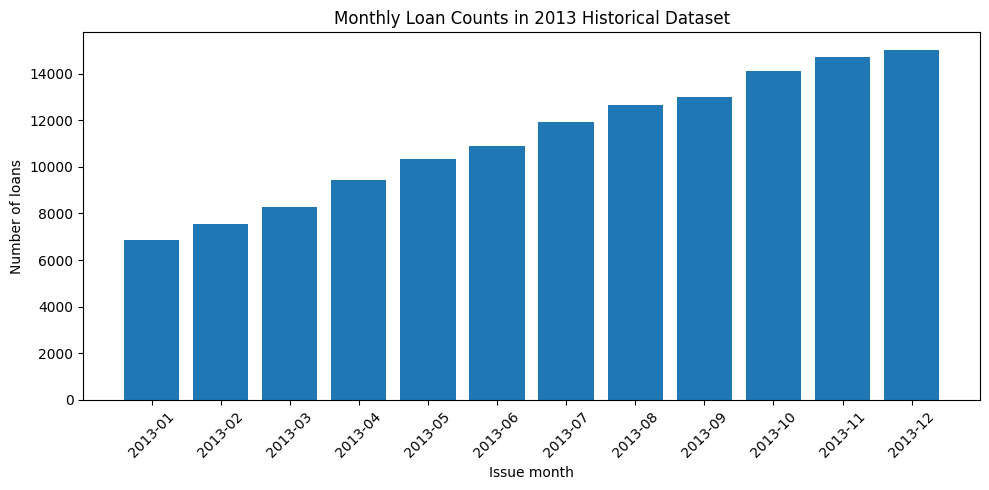

In [17]:
# Plot monthly loan counts in 2013
plt.figure(figsize=(10, 5))
plt.bar(historical_month_summary["issue_month"], historical_month_summary["rows"])
plt.xticks(rotation=45)
plt.xlabel("Issue month")
plt.ylabel("Number of loans")
plt.title("Monthly Loan Counts in 2013 Historical Dataset")
plt.tight_layout()
plt.show()

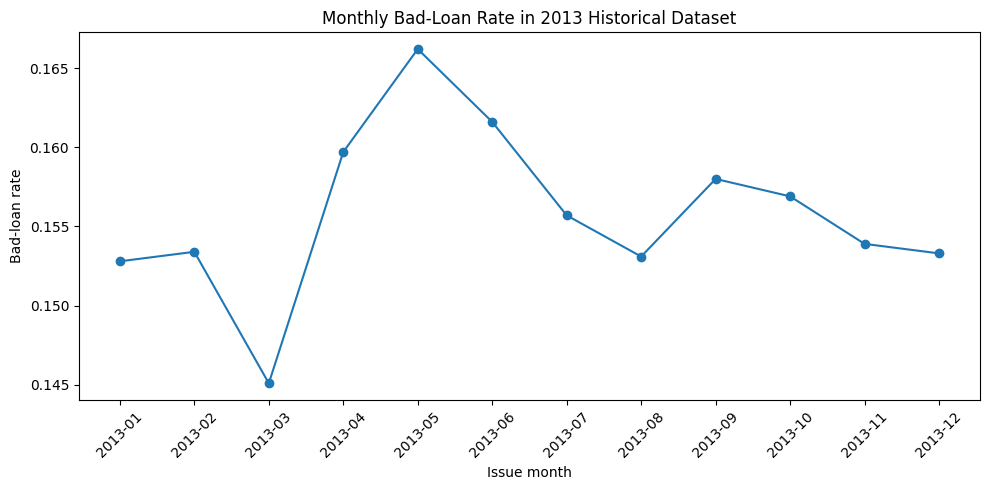

In [18]:
# Plot monthly bad-loan rate in 2013
plt.figure(figsize=(10, 5))
plt.plot(historical_month_summary["issue_month"], historical_month_summary["bad_loan_rate"], marker="o")
plt.xticks(rotation=45)
plt.xlabel("Issue month")
plt.ylabel("Bad-loan rate")
plt.title("Monthly Bad-Loan Rate in 2013 Historical Dataset")
plt.tight_layout()
plt.show()

## 3. Creating Train and Calibration Splits from 2013

2013 is split again in time: January to October for training, November and December for calibration. The calibration months are held back deliberately — they give an out-of-sample but pre-deployment view of the model, and their scores become the reference for prediction drift and the delayed performance baseline later in this notebook.

In [19]:
# Train on Jan-Oct, hold back Nov-Dec for calibration
train_df = historical_df[historical_df["issue_month"] <= "2013-10"].copy()
calibration_df = historical_df[historical_df["issue_month"] > "2013-10"].copy()

train_df = train_df.sort_values("issue_d").reset_index(drop=True)
calibration_df = calibration_df.sort_values("issue_d").reset_index(drop=True)

print("Training rows:", f"{len(train_df):,}")
print("Calibration rows:", f"{len(calibration_df):,}")
print("Total rows:", f"{len(train_df) + len(calibration_df):,}")
print("Original historical rows:", f"{len(historical_df):,}")

Training rows: 105,074
Calibration rows: 29,740
Total rows: 134,814
Original historical rows: 134,814


In [20]:
# Separate features, target, and time metadata for each split
X_train = train_df[final_feature_cols].copy()
y_train = train_df[target_col].copy()
train_time = train_df[time_cols].copy()

X_calibration = calibration_df[final_feature_cols].copy()
y_calibration = calibration_df[target_col].copy()
calibration_time = calibration_df[time_cols].copy()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_calibration shape:", X_calibration.shape)
print("y_calibration shape:", y_calibration.shape)
print("X_simulation shape:", X_simulation.shape)
print("y_simulation shape:", y_simulation.shape)

X_train shape: (105074, 69)
y_train shape: (105074,)
X_calibration shape: (29740, 69)
y_calibration shape: (29740,)
X_simulation shape: (1041560, 69)
y_simulation shape: (1041560,)


In [21]:
# Summarise the modelling splits
model_split_summary = pd.DataFrame({"split": ["train_2013_jan_oct", "calibration_2013_nov_dec", "simulation_2014_2016"],
                                    "rows": [len(train_df), len(calibration_df), len(simulation_df)],
                                    "start_date": [train_df["issue_d"].min(),
                                                   calibration_df["issue_d"].min(),
                                                   simulation_df["issue_d"].min()],
                                    "end_date": [train_df["issue_d"].max(),
                                                 calibration_df["issue_d"].max(),
                                                 simulation_df["issue_d"].max()],
                                    "bad_loan_rate": [y_train.mean().round(4),
                                                      y_calibration.mean().round(4),
                                                      y_simulation.mean().round(4)]})

display(model_split_summary)

,split,rows,start_date,end_date,bad_loan_rate
0,train_2013_jan_oct,105074,2013-01-01,2013-10-01,0.1566
1,calibration_2013_nov_dec,29740,2013-11-01,2013-12-01,0.1536
2,simulation_2014_2016,1041560,2014-01-01,2016-12-01,0.1925


In [22]:
# Check target balance in train, calibration, and simulation splits
target_balance_split = pd.DataFrame({
    "train_count": y_train.value_counts().sort_index(),
    "train_pct": y_train.value_counts(normalize=True).sort_index().mul(100).round(2),
    "calibration_count": y_calibration.value_counts().sort_index(),
    "calibration_pct": y_calibration.value_counts(normalize=True).sort_index().mul(100).round(2),
    "simulation_count": y_simulation.value_counts().sort_index(),
    "simulation_pct": y_simulation.value_counts(normalize=True).sort_index().mul(100).round(2)})

display(target_balance_split)

,train_count,train_pct,calibration_count,calibration_pct,simulation_count,simulation_pct
target_bad_loan,,,,,,
0,88615,84.34,25172,84.64,841018,80.75
1,16459,15.66,4568,15.36,200542,19.25


## 4. Preparing Native Categorical Features for XGBoost

Category levels are learned from the training period only. Any level that turns up later in the calibration or simulation data but was not seen in training is set to missing, so XGBoost sends it down the default branch. Learning levels from the full dataset instead would leak later information into the training setup.

In [23]:
# Rebuild from the clean splits so re-runs start from raw categories
X_train = train_df[final_feature_cols].copy()
y_train = train_df[target_col].copy()
train_time = train_df[time_cols].copy()

X_calibration = calibration_df[final_feature_cols].copy()
y_calibration = calibration_df[target_col].copy()
calibration_time = calibration_df[time_cols].copy()

X_simulation = simulation_df[final_feature_cols].copy()
y_simulation = simulation_df[target_col].copy()
simulation_time = simulation_df[time_cols].copy()

print("X_train shape:", X_train.shape)
print("X_calibration shape:", X_calibration.shape)
print("X_simulation shape:", X_simulation.shape)

X_train shape: (105074, 69)
X_calibration shape: (29740, 69)
X_simulation shape: (1041560, 69)


In [24]:
# Category levels come from the training period only
# Unseen levels become NaN and follow XGBoost's default branch

unseen_category_records = []
category_levels = {}

datasets_for_category_alignment = {"train": X_train,"calibration": X_calibration,"simulation": X_simulation}

for col in xgb_categorical_feature_cols:
    train_values = X_train[col].astype("string")
    train_categories = sorted(train_values.dropna().unique().tolist())
    category_levels[col] = train_categories

    for dataset_name, dataset in datasets_for_category_alignment.items():
        values = dataset[col].astype("string")
        unseen_mask = values.notna() & ~values.isin(train_categories)

        unseen_category_records.append({"feature": col,"dataset": dataset_name,
                                        "unseen_count": int(unseen_mask.sum()),
                                        "unseen_rate_pct": round(unseen_mask.mean() * 100, 4)})

        values = values.mask(unseen_mask, np.nan)
        dataset[col] = pd.Categorical(values, categories=train_categories)

In [25]:
# Review categories that were unseen relative to the training period
unseen_category_summary = pd.DataFrame(unseen_category_records)

display(unseen_category_summary)

,feature,dataset,unseen_count,unseen_rate_pct
0,home_ownership,train,0,0.0000
1,home_ownership,calibration,0,0.0000
2,home_ownership,simulation,108,0.0104
3,verification_status,train,0,0.0000
4,verification_status,calibration,0,0.0000
5,verification_status,simulation,0,0.0000
6,purpose,train,0,0.0000
7,purpose,calibration,0,0.0000
8,purpose,simulation,1,0.0001


In [26]:
# Levels must match across the three matrices
category_alignment_check = []

for col in xgb_categorical_feature_cols:
    train_categories = list(X_train[col].cat.categories)
    calibration_categories = list(X_calibration[col].cat.categories)
    simulation_categories = list(X_simulation[col].cat.categories)
    
    category_alignment_check.append({"feature": col,
                                     "train_categories": len(train_categories),
                                     "calibration_categories": len(calibration_categories),
                                     "simulation_categories": len(simulation_categories),
                                     "categories_match": train_categories == calibration_categories == simulation_categories})

category_alignment_check = pd.DataFrame(category_alignment_check)

display(category_alignment_check)

,feature,train_categories,calibration_categories,simulation_categories,categories_match
0,home_ownership,3,3,3,True
1,verification_status,3,3,3,True
2,purpose,13,13,13,True


In [27]:
# Confirm that all categorical features are category dtype after alignment
categorical_dtype_check_final = pd.DataFrame({
    "feature": xgb_categorical_feature_cols,
    "train_dtype": [str(X_train[col].dtype) for col in xgb_categorical_feature_cols],
    "calibration_dtype": [str(X_calibration[col].dtype) for col in xgb_categorical_feature_cols],
    "simulation_dtype": [str(X_simulation[col].dtype) for col in xgb_categorical_feature_cols]})

display(categorical_dtype_check_final)

,feature,train_dtype,calibration_dtype,simulation_dtype
0,home_ownership,category,category,category
1,verification_status,category,category,category
2,purpose,category,category,category


In [28]:
# Final missingness check before modelling
modelling_missing_check = pd.DataFrame({"dataset": ["train", "calibration", "simulation"],
                                        "total_feature_nans": [X_train.isna().sum().sum(),
                                                               X_calibration.isna().sum().sum(),
                                                               X_simulation.isna().sum().sum()],
                                        "numeric_feature_nans": [X_train[numeric_feature_cols].isna().sum().sum(),
                                                                 X_calibration[numeric_feature_cols].isna().sum().sum(),
                                                                 X_simulation[numeric_feature_cols].isna().sum().sum()],
                                        "categorical_feature_nans": [X_train[xgb_categorical_feature_cols].isna().sum().sum(),
                                                                     X_calibration[xgb_categorical_feature_cols].isna().sum().sum(),
                                                                     X_simulation[xgb_categorical_feature_cols].isna().sum().sum()],
                                        "target_nans": [y_train.isna().sum(),
                                                        y_calibration.isna().sum(),y_simulation.isna().sum()]})

display(modelling_missing_check)

,dataset,total_feature_nans,numeric_feature_nans,categorical_feature_nans,target_nans
0,train,0,0,0,0
1,calibration,0,0,0,0
2,simulation,109,0,109,0


Only a handful of unseen levels appear in the simulation period: the `ANY` level of `home_ownership` and a single `educational` `purpose` record, giving 109 missing categorical values out of 1,041,560 rows. That is negligible for scoring, and every simulation row can still be scored.

In [29]:
# Final input shape check before model training
model_input_summary = pd.DataFrame({"dataset": ["train", "calibration", "simulation"],
                                    "rows": [len(X_train), len(X_calibration), len(X_simulation)],
                                    "features": [X_train.shape[1], X_calibration.shape[1], X_simulation.shape[1]],
                                    "bad_loan_rate": [y_train.mean().round(4),y_calibration.mean().round(4),y_simulation.mean().round(4)]})

display(model_input_summary)

,dataset,rows,features,bad_loan_rate
0,train,105074,69,0.1566
1,calibration,29740,69,0.1536
2,simulation,1041560,69,0.1925


## 5. Training the Initial Champion Model

XGBoost is used because it handles tabular credit data well and supports categorical features natively. Two versions are fitted, one with `scale_pos_weight` and one without. So the effect of class weighting on probability quality can be seen directly.

In [30]:
# Imbalance weight from training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Training good loans:", f"{negative_count:,}")
print("Training bad loans:", f"{positive_count:,}")
print("scale_pos_weight:", round(scale_pos_weight, 3))

Training good loans: 88,615
Training bad loans: 16,459
scale_pos_weight: 5.384


In [31]:
# Define the initial champion XGBoost model
champion_model = XGBClassifier(objective="binary:logistic",eval_metric="logloss",
                               tree_method="hist",enable_categorical=True,n_estimators=500,
                               learning_rate=0.05,max_depth=4,min_child_weight=20, subsample=0.8,
                               colsample_bytree=0.8,reg_lambda=2.0, scale_pos_weight=scale_pos_weight,
                               random_state=42,n_jobs=-1)

champion_model

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fr

In [32]:
# Fit on Jan-Oct 2013 only
champion_model.fit(X_train,y_train,eval_set=[(X_train, y_train), (X_calibration, y_calibration)],verbose=50)

[HAMI-core Msg(631:139981271268672:libvgpu.c:839)]: Initializing.....
[HAMI-core Msg(631:139981271268672:libvgpu.c:855)]: Initialized


[0]	validation_0-logloss:0.68847	validation_1-logloss:0.68721
[50]	validation_0-logloss:0.63230	validation_1-logloss:0.61750
[100]	validation_0-logloss:0.62384	validation_1-logloss:0.61029
[150]	validation_0-logloss:0.61786	validation_1-logloss:0.60602
[200]	validation_0-logloss:0.61346	validation_1-logloss:0.60375
[250]	validation_0-logloss:0.60886	validation_1-logloss:0.60226
[300]	validation_0-logloss:0.60486	validation_1-logloss:0.60061
[350]	validation_0-logloss:0.60087	validation_1-logloss:0.59860
[400]	validation_0-logloss:0.59762	validation_1-logloss:0.59713
[450]	validation_0-logloss:0.59402	validation_1-logloss:0.59554
[499]	validation_0-logloss:0.59113	validation_1-logloss:0.59482


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fr

In [33]:
# Generate predicted bad-loan probabilities
train_pred_proba = champion_model.predict_proba(X_train)[:, 1]
calibration_pred_proba = champion_model.predict_proba(X_calibration)[:, 1]
simulation_pred_proba = champion_model.predict_proba(X_simulation)[:, 1]

print("Prediction ranges:")
print("Train:", train_pred_proba.min().round(4), "to", train_pred_proba.max().round(4))
print("Calibration:", calibration_pred_proba.min().round(4), "to", calibration_pred_proba.max().round(4))
print("Simulation:", simulation_pred_proba.min().round(4), "to", simulation_pred_proba.max().round(4))

Prediction ranges:
Train: 0.0048 to 0.9309
Calibration: 0.0155 to 0.8877
Simulation: 0.0068 to 0.9302


In [34]:
# INTERMEDIATE / SUPERSEDED
# Quick sanity check for the weighted model only
# This table is not used downstream and is superseded by champion_performance
# in Section 6, which is recalculated for the final selected champion model
quick_performance = pd.DataFrame({"dataset": ["train", "calibration", "simulation"],
                                  "roc_auc": [roc_auc_score(y_train, train_pred_proba),
                                              roc_auc_score(y_calibration, calibration_pred_proba),
                                              roc_auc_score(y_simulation, simulation_pred_proba)],
                                  "average_precision": [average_precision_score(y_train, train_pred_proba),
                                                        average_precision_score(y_calibration, calibration_pred_proba),
                                                        average_precision_score(y_simulation, simulation_pred_proba)],
                                  "log_loss": [log_loss(y_train, train_pred_proba),log_loss(y_calibration, calibration_pred_proba),
                                               log_loss(y_simulation, simulation_pred_proba)],
                                  "brier_score": [brier_score_loss(y_train, train_pred_proba),
                                                  brier_score_loss(y_calibration, calibration_pred_proba),
                                                  brier_score_loss(y_simulation, simulation_pred_proba)]})

display(quick_performance.round(4))

,dataset,roc_auc,average_precision,log_loss,brier_score
0,train,0.7580,0.3649,0.5911,0.2042
1,calibration,0.6980,0.2804,0.5948,0.2058
2,simulation,0.7066,0.3562,0.5706,0.1954


In [35]:
# Same settings without class weighting, for comparison
unweighted_model = XGBClassifier(objective="binary:logistic",eval_metric="logloss",
                                 tree_method="hist",enable_categorical=True,n_estimators=500,
                                 learning_rate=0.05, max_depth=4,min_child_weight=20,
                                 subsample=0.8,colsample_bytree=0.8,reg_lambda=2.0,
                                 random_state=42,n_jobs=-1)

unweighted_model.fit(X_train,y_train,eval_set=[(X_train, y_train), (X_calibration, y_calibration)],verbose=50)

[0]	validation_0-logloss:0.43142	validation_1-logloss:0.42648
[50]	validation_0-logloss:0.40139	validation_1-logloss:0.39872
[100]	validation_0-logloss:0.39676	validation_1-logloss:0.39729
[150]	validation_0-logloss:0.39371	validation_1-logloss:0.39693
[200]	validation_0-logloss:0.39127	validation_1-logloss:0.39666
[250]	validation_0-logloss:0.38898	validation_1-logloss:0.39645
[300]	validation_0-logloss:0.38671	validation_1-logloss:0.39625
[350]	validation_0-logloss:0.38500	validation_1-logloss:0.39630
[400]	validation_0-logloss:0.38327	validation_1-logloss:0.39625
[450]	validation_0-logloss:0.38161	validation_1-logloss:0.39614
[499]	validation_0-logloss:0.38005	validation_1-logloss:0.39618


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fr

In [36]:
# Generate predictions from the unweighted model
train_pred_proba_unweighted = unweighted_model.predict_proba(X_train)[:, 1]
calibration_pred_proba_unweighted = unweighted_model.predict_proba(X_calibration)[:, 1]
simulation_pred_proba_unweighted = unweighted_model.predict_proba(X_simulation)[:, 1]

# Compare weighted and unweighted models
model_comparison = pd.DataFrame({"model": ["weighted_xgboost", "weighted_xgboost", "weighted_xgboost",
                                           "unweighted_xgboost", "unweighted_xgboost", "unweighted_xgboost"],
                                 "dataset": ["train", "calibration", "simulation",
                                             "train", "calibration", "simulation"],
                                 "roc_auc": [roc_auc_score(y_train, train_pred_proba),
                                             roc_auc_score(y_calibration, calibration_pred_proba),
                                             roc_auc_score(y_simulation, simulation_pred_proba),
                                             roc_auc_score(y_train, train_pred_proba_unweighted),
                                             roc_auc_score(y_calibration, calibration_pred_proba_unweighted),
                                             roc_auc_score(y_simulation, simulation_pred_proba_unweighted)],
                                 "average_precision": [average_precision_score(y_train, train_pred_proba),
                                                       average_precision_score(y_calibration, calibration_pred_proba),
                                                       average_precision_score(y_simulation, simulation_pred_proba),
                                                       average_precision_score(y_train, train_pred_proba_unweighted),
                                                       average_precision_score(y_calibration, calibration_pred_proba_unweighted),
                                                       average_precision_score(y_simulation, simulation_pred_proba_unweighted)],
                                 "log_loss": [log_loss(y_train, train_pred_proba),
                                              log_loss(y_calibration, calibration_pred_proba),
                                              log_loss(y_simulation, simulation_pred_proba),
                                              log_loss(y_train, train_pred_proba_unweighted),
                                              log_loss(y_calibration, calibration_pred_proba_unweighted),
                                              log_loss(y_simulation, simulation_pred_proba_unweighted)],
                                 "brier_score": [brier_score_loss(y_train, train_pred_proba),
                                                 brier_score_loss(y_calibration, calibration_pred_proba),
                                                 brier_score_loss(y_simulation, simulation_pred_proba),
                                                 brier_score_loss(y_train, train_pred_proba_unweighted),
                                                 brier_score_loss(y_calibration, calibration_pred_proba_unweighted),
                                                 brier_score_loss(y_simulation, simulation_pred_proba_unweighted)],
                                 "mean_predicted_probability": [train_pred_proba.mean(),
                                                                calibration_pred_proba.mean(),
                                                                simulation_pred_proba.mean(),
                                                                train_pred_proba_unweighted.mean(),
                                                                calibration_pred_proba_unweighted.mean(),
                                                                simulation_pred_proba_unweighted.mean()],
                                 "actual_bad_loan_rate": [y_train.mean(),
                                                          y_calibration.mean(),
                                                          y_simulation.mean(),
                                                          y_train.mean(),
                                                          y_calibration.mean(),
                                                          y_simulation.mean()]})

display(model_comparison.round(4))

,model,dataset,roc_auc,average_precision,log_loss,brier_score,mean_predicted_probability,actual_bad_loan_rate
0,weighted_xgboost,train,0.7580,0.3649,0.5911,0.2042,0.4436,0.1566
1,weighted_xgboost,calibration,0.6980,0.2804,0.5948,0.2058,0.4270,0.1536
2,weighted_xgboost,simulation,0.7066,0.3562,0.5706,0.1954,0.4074,0.1925
3,unweighted_xgboost,train,0.7514,0.3745,0.3801,0.1170,0.1566,0.1566
4,unweighted_xgboost,calibration,0.6998,0.2835,0.3962,0.1215,0.1499,0.1536
5,unweighted_xgboost,simulation,0.7084,0.3580,0.4561,0.1444,0.1443,0.1925


In [37]:
# Unweighted model selected on calibration quality
weighted_model = champion_model

weighted_train_pred_proba = train_pred_proba
weighted_calibration_pred_proba = calibration_pred_proba
weighted_simulation_pred_proba = simulation_pred_proba

champion_model_name = "unweighted_xgboost"
champion_model = unweighted_model

train_pred_proba = train_pred_proba_unweighted
calibration_pred_proba = calibration_pred_proba_unweighted
simulation_pred_proba = simulation_pred_proba_unweighted

champion_selection_summary = model_comparison[
    model_comparison["model"] == champion_model_name
].copy()

display(champion_selection_summary.round(4))

,model,dataset,roc_auc,average_precision,log_loss,brier_score,mean_predicted_probability,actual_bad_loan_rate
3,unweighted_xgboost,train,0.7514,0.3745,0.3801,0.1170,0.1566,0.1566
4,unweighted_xgboost,calibration,0.6998,0.2835,0.3962,0.1215,0.1499,0.1536
5,unweighted_xgboost,simulation,0.7084,0.3580,0.4561,0.1444,0.1443,0.1925


Class weighting does not help here. Ranking is effectively unchanged (calibration ROC AUC 0.698 weighted against 0.700 unweighted), but the weighted model predicts a mean probability of about 0.43 against an actual bad-loan rate of about 0.15, and its Brier score is 0.206 rather than 0.122. Re-weighting the positive class pushes the output away from the true marginal rate.

Since this project is about probability reliability under drift, not only ranking, the unweighted model is the sensible champion. The weighted model is kept as a comparison artefact, and class imbalance is dealt with at evaluation time through calibration gap, Brier score and log loss alongside Receiver Operating Characteristic Area Under the Curve (ROC AUC) and average precision.

## 6. Evaluating Champion Model Performance

Performance is reported on the training period, the calibration period and the out-of-time simulation stream, which separates fit from temporal generalisation and gives a first look at how the model behaves on later data.

In [38]:
# Summarise selected champion model performance
champion_performance = pd.DataFrame({"dataset": ["train", "calibration", "simulation"],
                                     "rows": [len(y_train), len(y_calibration), len(y_simulation)],
                                     "actual_bad_loan_rate": [y_train.mean(),
                                                              y_calibration.mean(),
                                                              y_simulation.mean()],
                                     "mean_predicted_probability": [train_pred_proba.mean(),
                                                                    calibration_pred_proba.mean(),
                                                                    simulation_pred_proba.mean()],
                                     "roc_auc": [roc_auc_score(y_train, train_pred_proba),
                                                 roc_auc_score(y_calibration, calibration_pred_proba),
                                                 roc_auc_score(y_simulation, simulation_pred_proba)],
                                     "average_precision": [average_precision_score(y_train, train_pred_proba),
                                                           average_precision_score(y_calibration, calibration_pred_proba),
                                                           average_precision_score(y_simulation, simulation_pred_proba)],
                                     "log_loss": [log_loss(y_train, train_pred_proba),
                                                  log_loss(y_calibration, calibration_pred_proba),
                                                  log_loss(y_simulation, simulation_pred_proba)],
                                     "brier_score": [brier_score_loss(y_train, train_pred_proba),
                                                     brier_score_loss(y_calibration, calibration_pred_proba),
                                                     brier_score_loss(y_simulation, simulation_pred_proba)]})

champion_performance["calibration_gap"] = (champion_performance["actual_bad_loan_rate"] -champion_performance["mean_predicted_probability"])

display(champion_performance.round(4))

,dataset,rows,actual_bad_loan_rate,mean_predicted_probability,roc_auc,average_precision,log_loss,brier_score,calibration_gap
0,train,105074,0.1566,0.1566,0.7514,0.3745,0.3801,0.1170,0.0000
1,calibration,29740,0.1536,0.1499,0.6998,0.2835,0.3962,0.1215,0.0037
2,simulation,1041560,0.1925,0.1443,0.7084,0.3580,0.4561,0.1444,0.0483


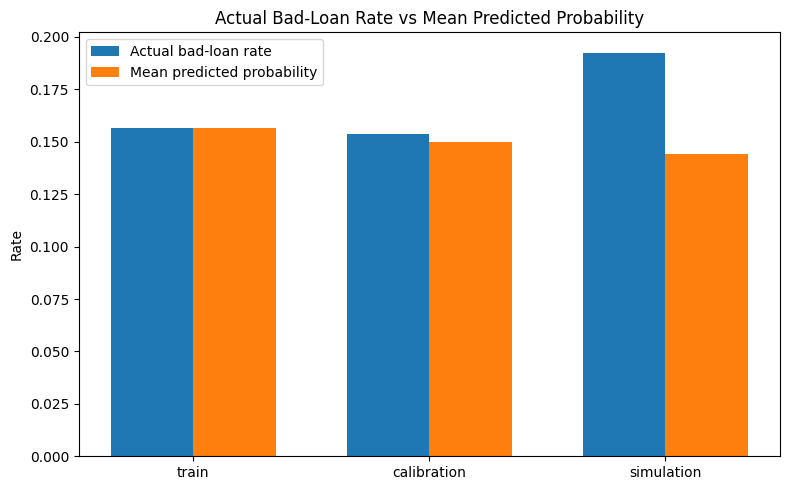

In [39]:
# Compare actual bad-loan rate with mean predicted probability
plot_df = champion_performance[["dataset","actual_bad_loan_rate","mean_predicted_probability"]].copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width / 2, plot_df["actual_bad_loan_rate"], width, label="Actual bad-loan rate")
plt.bar(x + width / 2, plot_df["mean_predicted_probability"], width, label="Mean predicted probability")
plt.xticks(x, plot_df["dataset"])
plt.ylabel("Rate")
plt.title("Actual Bad-Loan Rate vs Mean Predicted Probability")
plt.legend()
plt.tight_layout()
plt.show()

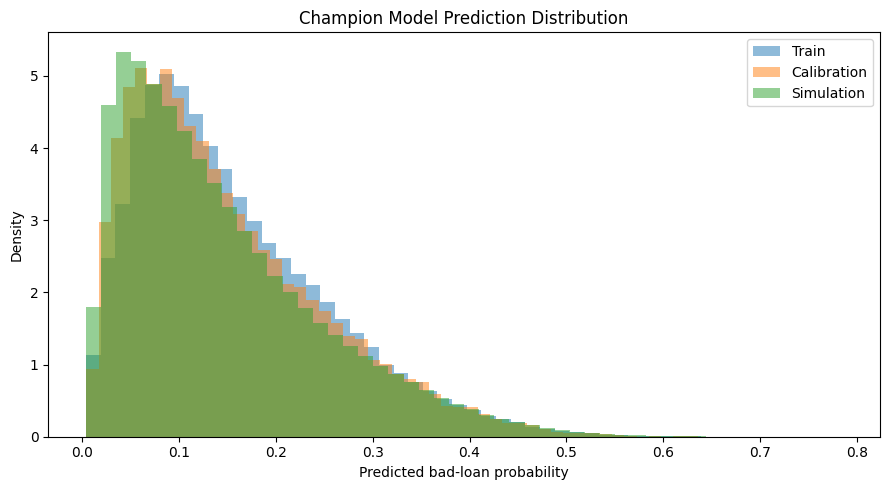

In [40]:
# Compare predicted probability distributions across datasets
plt.figure(figsize=(9, 5))
plt.hist(train_pred_proba, bins=50, alpha=0.5, density=True, label="Train")
plt.hist(calibration_pred_proba, bins=50, alpha=0.5, density=True, label="Calibration")
plt.hist(simulation_pred_proba, bins=50, alpha=0.5, density=True, label="Simulation")
plt.xlabel("Predicted bad-loan probability")
plt.ylabel("Density")
plt.title("Champion Model Prediction Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [41]:
# Summarise prediction distributions
prediction_distribution_summary = pd.DataFrame({"dataset": ["train", "calibration", "simulation"],
                                                "mean": [train_pred_proba.mean(),
                                                         calibration_pred_proba.mean(),
                                                         simulation_pred_proba.mean()],
                                                "std": [train_pred_proba.std(),
                                                        calibration_pred_proba.std(),
                                                        simulation_pred_proba.std()],
                                                "min": [train_pred_proba.min(),
                                                        calibration_pred_proba.min(),
                                                        simulation_pred_proba.min()],
                                                "p25": [np.percentile(train_pred_proba, 25),
                                                        np.percentile(calibration_pred_proba, 25),
                                                        np.percentile(simulation_pred_proba, 25)],
                                                "median": [np.percentile(train_pred_proba, 50),
                                                           np.percentile(calibration_pred_proba, 50),
                                                           np.percentile(simulation_pred_proba, 50)],
                                                "p75": [np.percentile(train_pred_proba, 75),
                                                        np.percentile(calibration_pred_proba, 75),
                                                        np.percentile(simulation_pred_proba, 75)],
                                                "max": [train_pred_proba.max(),
                                                        calibration_pred_proba.max(),
                                                        simulation_pred_proba.max()]})

display(prediction_distribution_summary.round(4))

,dataset,mean,std,min,p25,median,p75,max
0,train,0.1566,0.0995,0.0037,0.0806,0.1343,0.2149,0.7603
1,calibration,0.1499,0.1004,0.0041,0.0717,0.1257,0.2077,0.6357
2,simulation,0.1443,0.1036,0.0037,0.0633,0.1184,0.2009,0.7850


## 7. Feature Importance and Model Interpretation

Importance is used for interpretation and to pick the priority features for the drift narrative. The monitoring still covers the whole feature set. The top features just make the alerts easier to read.

In [42]:
# Confirm the selected champion model before calculating feature importance
print("Champion model:", champion_model_name)
print(champion_model)

Champion model: unweighted_xgboost
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=20, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=500, n_jobs=-1,
              num_parallel_tree=None, ...)


In [43]:
# Gain, weight and cover importance
booster = champion_model.get_booster()

def get_importance_with_feature_names(booster, feature_names, importance_type):
    raw_scores = booster.get_score(importance_type=importance_type)
    values = []
    
    for i, feature in enumerate(feature_names):
        # XGBoost usually keeps real feature names from Pandas
        # This fallback handles cases where names appear as f0, f1, etc.
        value = raw_scores.get(feature, raw_scores.get(f"f{i}", 0))
        values.append(value)
    
    return values

In [44]:
# Calculate gain, weight and cover importance
feature_importance = pd.DataFrame({"feature": final_feature_cols,
                                   "gain": get_importance_with_feature_names(booster, final_feature_cols, "gain"),
                                   "weight": get_importance_with_feature_names(booster, final_feature_cols, "weight"),
                                   "cover": get_importance_with_feature_names(booster, final_feature_cols, "cover")})

feature_importance["gain_pct"] = (feature_importance["gain"] / feature_importance["gain"].sum() * 100)

feature_importance["feature_type"] = np.where(feature_importance["feature"].isin(xgb_categorical_feature_cols),"categorical","numeric")

feature_importance = feature_importance.sort_values("gain", ascending=False)

display(feature_importance.head(20).round(4))

,feature,gain,weight,cover,gain_pct,feature_type
4,sub_grade,165.2376,98.0,4769.6362,16.9754,numeric
3,grade,144.8314,13.0,5021.0376,14.8790,numeric
1,int_rate,100.2333,248.0,3882.3176,10.2973,numeric
7,annual_inc,20.2138,351.0,3108.0945,2.0766,numeric
10,dti,16.0253,226.0,3609.7007,1.6463,numeric
0,loan_amnt,15.7209,330.0,4374.0098,1.6151,numeric
8,verification_status,15.2406,53.0,4928.8047,1.5657,categorical
25,acc_open_past_24mths,15.0805,161.0,4120.1807,1.5493,numeric
36,mths_since_recent_bc,13.2421,167.0,3222.9185,1.3604,numeric
2,installment,12.7858,281.0,3530.2664,1.3135,numeric


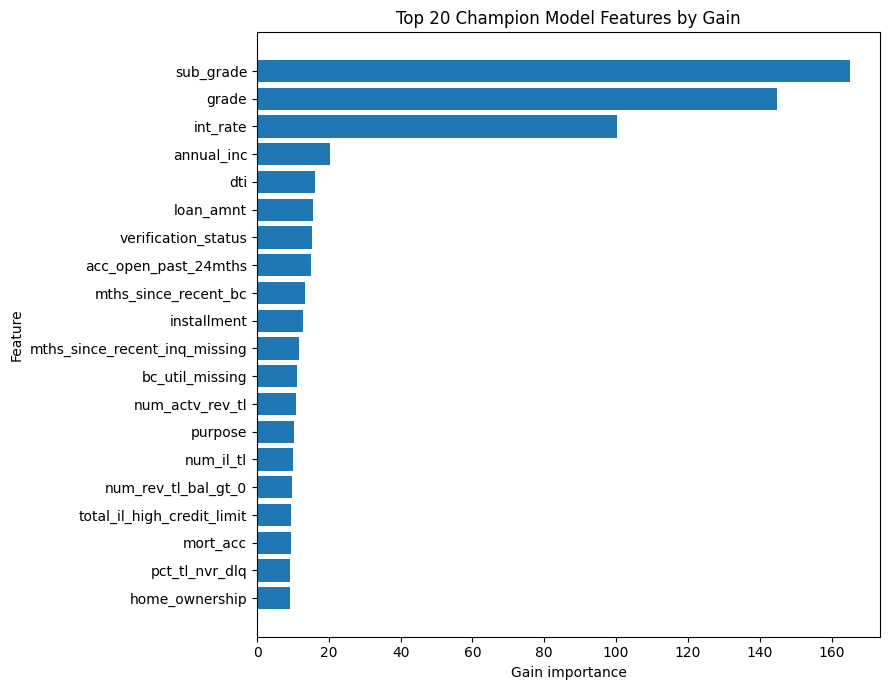

In [45]:
# Plot the top 20 features by gain importance
top_n = 20
top_features = feature_importance.head(top_n).sort_values("gain")

plt.figure(figsize=(9, 7))
plt.barh(top_features["feature"], top_features["gain"])
plt.xlabel("Gain importance")
plt.ylabel("Feature")
plt.title("Top 20 Champion Model Features by Gain")
plt.tight_layout()
plt.show()

In [46]:
# Summarise total importance by numeric and categorical feature type
importance_by_type = (feature_importance.groupby("feature_type")
    .agg(total_gain=("gain", "sum"),total_gain_pct=("gain_pct", "sum"),feature_count=("feature", "count"))
    .sort_values("total_gain", ascending=False))

display(importance_by_type.round(4))

,total_gain,total_gain_pct,feature_count
feature_type,,,
numeric,938.836,96.4496,66
categorical,34.559,3.5504,3


In [47]:
# Top features used to focus the drift narrative
priority_monitoring_features = feature_importance.head(20)["feature"].tolist()

print("Priority monitoring features:")
print(priority_monitoring_features)

Priority monitoring features:
['sub_grade', 'grade', 'int_rate', 'annual_inc', 'dti', 'loan_amnt', 'verification_status', 'acc_open_past_24mths', 'mths_since_recent_bc', 'installment', 'mths_since_recent_inq_missing', 'bc_util_missing', 'num_actv_rev_tl', 'purpose', 'num_il_tl', 'num_rev_tl_bal_gt_0', 'total_il_high_credit_limit', 'mort_acc', 'pct_tl_nvr_dlq', 'home_ownership']


### Redundancy Check: Grade, Sub-Grade and Interest Rate

`sub_grade`, `int_rate` and `grade` dominate the importance table, which is unsurprising: grade and sub-grade are Lending Club's risk bands and the rate is set from them. Keeping all three makes importance harder to read and would produce three drift alerts for what is really one signal, so I test the alternatives of keeping just one of them.

In [48]:
# Drop the duplicated risk/pricing signals
redundant_risk_pricing_cols = ["grade", "int_rate"]

reduced_feature_cols = [col for col in final_feature_cols if col not in redundant_risk_pricing_cols]

print("Original feature count:", len(final_feature_cols))
print("Reduced feature count:", len(reduced_feature_cols))
print("Removed columns:", redundant_risk_pricing_cols)

Original feature count: 69
Reduced feature count: 67
Removed columns: ['grade', 'int_rate']


In [49]:
# Build reduced feature matrices
X_train_reduced = X_train[reduced_feature_cols].copy()
X_calibration_reduced = X_calibration[reduced_feature_cols].copy()
X_simulation_reduced = X_simulation[reduced_feature_cols].copy()

print("X_train_reduced shape:", X_train_reduced.shape)
print("X_calibration_reduced shape:", X_calibration_reduced.shape)
print("X_simulation_reduced shape:", X_simulation_reduced.shape)

X_train_reduced shape: (105074, 67)
X_calibration_reduced shape: (29740, 67)
X_simulation_reduced shape: (1041560, 67)


In [50]:
# Train reduced unweighted XGBoost model
reduced_unweighted_model = XGBClassifier(objective="binary:logistic",eval_metric="logloss",
                                         tree_method="hist", enable_categorical=True,
                                         n_estimators=500, learning_rate=0.05, max_depth=4,
                                         min_child_weight=20, subsample=0.8, colsample_bytree=0.8, 
                                         reg_lambda=2.0,random_state=42, n_jobs=-1)

reduced_unweighted_model.fit(X_train_reduced,y_train, eval_set=[(X_train_reduced, y_train), (X_calibration_reduced, y_calibration)],verbose=50)

[0]	validation_0-logloss:0.43145	validation_1-logloss:0.42646
[50]	validation_0-logloss:0.40154	validation_1-logloss:0.39908
[100]	validation_0-logloss:0.39678	validation_1-logloss:0.39752
[150]	validation_0-logloss:0.39380	validation_1-logloss:0.39705
[200]	validation_0-logloss:0.39136	validation_1-logloss:0.39688
[250]	validation_0-logloss:0.38911	validation_1-logloss:0.39667
[300]	validation_0-logloss:0.38693	validation_1-logloss:0.39660
[350]	validation_0-logloss:0.38519	validation_1-logloss:0.39653
[400]	validation_0-logloss:0.38340	validation_1-logloss:0.39653
[450]	validation_0-logloss:0.38173	validation_1-logloss:0.39644
[499]	validation_0-logloss:0.38018	validation_1-logloss:0.39642


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fr

In [51]:
# Generate predictions from the reduced model
train_pred_proba_reduced = reduced_unweighted_model.predict_proba(X_train_reduced)[:, 1]
calibration_pred_proba_reduced = reduced_unweighted_model.predict_proba(X_calibration_reduced)[:, 1]
simulation_pred_proba_reduced = reduced_unweighted_model.predict_proba(X_simulation_reduced)[:, 1]

print("Prediction ranges:")
print("Train:", train_pred_proba_reduced.min().round(4), "to", train_pred_proba_reduced.max().round(4))
print("Calibration:", calibration_pred_proba_reduced.min().round(4), "to", calibration_pred_proba_reduced.max().round(4))
print("Simulation:", simulation_pred_proba_reduced.min().round(4), "to", simulation_pred_proba_reduced.max().round(4))

Prediction ranges:
Train: 0.0036 to 0.7457
Calibration: 0.0049 to 0.6614
Simulation: 0.0032 to 0.7763


In [52]:
# Compare full and reduced unweighted models
full_vs_reduced_comparison = pd.DataFrame({"model": ["full_unweighted_xgboost",
                                                     "full_unweighted_xgboost",
                                                     "full_unweighted_xgboost",
                                                     "reduced_unweighted_xgboost",
                                                     "reduced_unweighted_xgboost",
                                                     "reduced_unweighted_xgboost"],
                                           "dataset": ["train", "calibration", "simulation",
                                                       "train", "calibration", "simulation"],
                                           "feature_count": [len(final_feature_cols),
                                                             len(final_feature_cols),
                                                             len(final_feature_cols),
                                                             len(reduced_feature_cols),
                                                             len(reduced_feature_cols),
                                                             len(reduced_feature_cols)],
                                           "roc_auc": [roc_auc_score(y_train, train_pred_proba),
                                                       roc_auc_score(y_calibration, calibration_pred_proba),
                                                       roc_auc_score(y_simulation, simulation_pred_proba),
                                                       roc_auc_score(y_train, train_pred_proba_reduced),
                                                       roc_auc_score(y_calibration, calibration_pred_proba_reduced),
                                                       roc_auc_score(y_simulation, simulation_pred_proba_reduced)],
                                           "average_precision": [average_precision_score(y_train, train_pred_proba),
                                                                 average_precision_score(y_calibration, calibration_pred_proba),
                                                                 average_precision_score(y_simulation, simulation_pred_proba),
                                                                 average_precision_score(y_train, train_pred_proba_reduced),
                                                                 average_precision_score(y_calibration, calibration_pred_proba_reduced),
                                                                 average_precision_score(y_simulation, simulation_pred_proba_reduced)],
                                           "log_loss": [log_loss(y_train, train_pred_proba),
                                                        log_loss(y_calibration, calibration_pred_proba),
                                                        log_loss(y_simulation, simulation_pred_proba),
                                                        log_loss(y_train, train_pred_proba_reduced),
                                                        log_loss(y_calibration, calibration_pred_proba_reduced),
                                                        log_loss(y_simulation, simulation_pred_proba_reduced)],
                                           "brier_score": [brier_score_loss(y_train, train_pred_proba),
                                                           brier_score_loss(y_calibration, calibration_pred_proba),
                                                           brier_score_loss(y_simulation, simulation_pred_proba),
                                                           brier_score_loss(y_train, train_pred_proba_reduced),
                                                           brier_score_loss(y_calibration, calibration_pred_proba_reduced),
                                                           brier_score_loss(y_simulation, simulation_pred_proba_reduced)],
                                           "mean_predicted_probability": [train_pred_proba.mean(),
                                                                          calibration_pred_proba.mean(),
                                                                          simulation_pred_proba.mean(),
                                                                          train_pred_proba_reduced.mean(),
                                                                          calibration_pred_proba_reduced.mean(),
                                                                          simulation_pred_proba_reduced.mean()],
                                           "actual_bad_loan_rate": [y_train.mean(),
                                                                    y_calibration.mean(),
                                                                    y_simulation.mean(),
                                                                    y_train.mean(),
                                                                    y_calibration.mean(),
                                                                    y_simulation.mean()]})

display(full_vs_reduced_comparison.round(4))

,model,dataset,feature_count,roc_auc,average_precision,log_loss,brier_score,mean_predicted_probability,actual_bad_loan_rate
0,full_unweighted_xgboost,train,69,0.7514,0.3745,0.3801,0.1170,0.1566,0.1566
1,full_unweighted_xgboost,calibration,69,0.6998,0.2835,0.3962,0.1215,0.1499,0.1536
2,full_unweighted_xgboost,simulation,69,0.7084,0.3580,0.4561,0.1444,0.1443,0.1925
3,reduced_unweighted_xgboost,train,67,0.7509,0.3747,0.3802,0.1170,0.1566,0.1566
4,reduced_unweighted_xgboost,calibration,67,0.6990,0.2812,0.3964,0.1216,0.1511,0.1536
5,reduced_unweighted_xgboost,simulation,67,0.7085,0.3568,0.4507,0.1432,0.1584,0.1925


In [53]:
# Keep exactly one risk signal in each variant
risk_signal_variants = {"keep_sub_grade_only": ["grade", "int_rate"],
                        "keep_grade_only": ["sub_grade", "int_rate"],
                        "keep_int_rate_only": ["grade", "sub_grade"]}

variant_results = []
variant_models = {}
variant_predictions = {}

In [54]:
# Create an XGBoost model using the champion settings
def create_risk_signal_model():
    return XGBClassifier(objective="binary:logistic",
                         eval_metric="logloss",
                         tree_method="hist",
                         enable_categorical=True,
                         n_estimators=500,
                         learning_rate=0.05,
                         max_depth=4,
                         min_child_weight=20,
                         subsample=0.8,
                         colsample_bytree=0.8,
                         reg_lambda=2.0,
                         random_state=42,
                         n_jobs=-1)

In [55]:
# Train each risk-signal variant
for variant_name, cols_to_drop in risk_signal_variants.items():
    print(f"\nTraining variant: {variant_name}")
    print("Dropped columns:", cols_to_drop)

    variant_feature_cols = [col for col in final_feature_cols if col not in cols_to_drop]

    X_train_variant = X_train[variant_feature_cols].copy()
    X_calibration_variant = X_calibration[variant_feature_cols].copy()
    X_simulation_variant = X_simulation[variant_feature_cols].copy()

    variant_model = create_risk_signal_model()

    variant_model.fit(X_train_variant,
                      y_train,
                      eval_set=[(X_train_variant, y_train),
                                (X_calibration_variant, y_calibration)],
                      verbose=False)

    train_pred = variant_model.predict_proba(X_train_variant)[:, 1]
    calibration_pred = variant_model.predict_proba(X_calibration_variant)[:, 1]
    simulation_pred = variant_model.predict_proba(X_simulation_variant)[:, 1]

    variant_models[variant_name] = variant_model
    variant_predictions[variant_name] = {"feature_cols": variant_feature_cols,
                                         "train_pred": train_pred,
                                         "calibration_pred": calibration_pred,
                                         "simulation_pred": simulation_pred}


Training variant: keep_sub_grade_only
Dropped columns: ['grade', 'int_rate']

Training variant: keep_grade_only
Dropped columns: ['sub_grade', 'int_rate']

Training variant: keep_int_rate_only
Dropped columns: ['grade', 'sub_grade']


In [56]:
# Evaluate each variant across all datasets
dataset_targets = {"train": y_train,
                   "calibration": y_calibration,
                   "simulation": y_simulation}

for variant_name, predictions in variant_predictions.items():
    variant_feature_cols = predictions["feature_cols"]

    for dataset_name, y_true in dataset_targets.items():
        y_pred = predictions[f"{dataset_name}_pred"]

        variant_results.append({"model": variant_name,
                                "dataset": dataset_name,
                                "feature_count": len(variant_feature_cols),
                                "roc_auc": roc_auc_score(y_true, y_pred),
                                "average_precision": average_precision_score(y_true, y_pred),
                                "log_loss": log_loss(y_true, y_pred),
                                "brier_score": brier_score_loss(y_true, y_pred),
                                "mean_predicted_probability": y_pred.mean(),
                                "actual_bad_loan_rate": y_true.mean(),
                                "calibration_gap": y_true.mean() - y_pred.mean()})

risk_signal_comparison = pd.DataFrame(variant_results)

display(risk_signal_comparison.round(4))

,model,dataset,feature_count,roc_auc,average_precision,log_loss,brier_score,mean_predicted_probability,actual_bad_loan_rate,calibration_gap
0,keep_sub_grade_only,train,67,0.7509,0.3747,0.3802,0.1170,0.1566,0.1566,0.0000
1,keep_sub_grade_only,calibration,67,0.6990,0.2812,0.3964,0.1216,0.1511,0.1536,0.0025
2,keep_sub_grade_only,simulation,67,0.7085,0.3568,0.4507,0.1432,0.1584,0.1925,0.0342
3,keep_grade_only,train,67,0.7506,0.3722,0.3806,0.1171,0.1566,0.1566,0.0000
4,keep_grade_only,calibration,67,0.6981,0.2820,0.3968,0.1217,0.1522,0.1536,0.0014
5,keep_grade_only,simulation,67,0.7089,0.3575,0.4502,0.1431,0.1595,0.1925,0.0331
6,keep_int_rate_only,train,67,0.7521,0.3744,0.3799,0.1169,0.1566,0.1566,0.0000
7,keep_int_rate_only,calibration,67,0.6988,0.2838,0.3964,0.1216,0.1502,0.1536,0.0034
8,keep_int_rate_only,simulation,67,0.7080,0.3579,0.4591,0.1453,0.1379,0.1925,0.0546


In [57]:
# Add the original full model results for comparison
full_model_rows = []

for dataset_name, y_true, y_pred in [("train", y_train, train_pred_proba),
                                     ("calibration", y_calibration, calibration_pred_proba),
                                     ("simulation", y_simulation, simulation_pred_proba)]:
    full_model_rows.append({"model": "full_model_all_three",
                            "dataset": dataset_name,
                            "feature_count": len(final_feature_cols),
                            "roc_auc": roc_auc_score(y_true, y_pred),
                            "average_precision": average_precision_score(y_true, y_pred),
                            "log_loss": log_loss(y_true, y_pred),
                            "brier_score": brier_score_loss(y_true, y_pred),
                            "mean_predicted_probability": y_pred.mean(),
                            "actual_bad_loan_rate": y_true.mean(),
                            "calibration_gap": y_true.mean() - y_pred.mean()})

risk_signal_comparison_all = pd.concat([pd.DataFrame(full_model_rows),risk_signal_comparison], ignore_index=True)

display(risk_signal_comparison_all.round(4))

,model,dataset,feature_count,roc_auc,average_precision,log_loss,brier_score,mean_predicted_probability,actual_bad_loan_rate,calibration_gap
0,full_model_all_three,train,69,0.7514,0.3745,0.3801,0.1170,0.1566,0.1566,0.0000
1,full_model_all_three,calibration,69,0.6998,0.2835,0.3962,0.1215,0.1499,0.1536,0.0037
2,full_model_all_three,simulation,69,0.7084,0.3580,0.4561,0.1444,0.1443,0.1925,0.0483
3,keep_sub_grade_only,train,67,0.7509,0.3747,0.3802,0.1170,0.1566,0.1566,0.0000
4,keep_sub_grade_only,calibration,67,0.6990,0.2812,0.3964,0.1216,0.1511,0.1536,0.0025
5,keep_sub_grade_only,simulation,67,0.7085,0.3568,0.4507,0.1432,0.1584,0.1925,0.0342
6,keep_grade_only,train,67,0.7506,0.3722,0.3806,0.1171,0.1566,0.1566,0.0000
7,keep_grade_only,calibration,67,0.6981,0.2820,0.3968,0.1217,0.1522,0.1536,0.0014
8,keep_grade_only,simulation,67,0.7089,0.3575,0.4502,0.1431,0.1595,0.1925,0.0331
9,keep_int_rate_only,train,67,0.7521,0.3744,0.3799,0.1169,0.1566,0.1566,0.0000


In [58]:
# Judge the variants out of sample, not on train
decision_table = risk_signal_comparison_all[risk_signal_comparison_all["dataset"].isin(["calibration", "simulation"])].copy()

decision_table = decision_table.sort_values(["dataset", "roc_auc"], ascending=[True, False])

display(decision_table.round(4))

,model,dataset,feature_count,roc_auc,average_precision,log_loss,brier_score,mean_predicted_probability,actual_bad_loan_rate,calibration_gap
1,full_model_all_three,calibration,69,0.6998,0.2835,0.3962,0.1215,0.1499,0.1536,0.0037
4,keep_sub_grade_only,calibration,67,0.6990,0.2812,0.3964,0.1216,0.1511,0.1536,0.0025
10,keep_int_rate_only,calibration,67,0.6988,0.2838,0.3964,0.1216,0.1502,0.1536,0.0034
7,keep_grade_only,calibration,67,0.6981,0.2820,0.3968,0.1217,0.1522,0.1536,0.0014
8,keep_grade_only,simulation,67,0.7089,0.3575,0.4502,0.1431,0.1595,0.1925,0.0331
5,keep_sub_grade_only,simulation,67,0.7085,0.3568,0.4507,0.1432,0.1584,0.1925,0.0342
2,full_model_all_three,simulation,69,0.7084,0.3580,0.4561,0.1444,0.1443,0.1925,0.0483
11,keep_int_rate_only,simulation,67,0.7080,0.3579,0.4591,0.1453,0.1379,0.1925,0.0546


All four variants perform almost identically out of sample — calibration ROC AUC sits between 0.698 and 0.700, and simulation ROC AUC between 0.708 and 0.709. Since dropping `grade` and `int_rate` costs essentially nothing, I take the `keep_sub_grade_only` set as the champion: it keeps one clean risk-band signal and avoids three correlated features raising the same drift alert.

In [59]:
# Final champion assignment
# From this point onward, champion_model refers to the selected keep_sub_grade_only model
# Do not re-run earlier intermediate model-assignment cells after this point
# Final champion model feature set
champion_model_name = "keep_sub_grade_only"
champion_model = variant_models[champion_model_name]

champion_feature_cols = variant_predictions[champion_model_name]["feature_cols"]

X_train_champion = X_train[champion_feature_cols].copy()
X_calibration_champion = X_calibration[champion_feature_cols].copy()
X_simulation_champion = X_simulation[champion_feature_cols].copy()

train_pred_proba = variant_predictions[champion_model_name]["train_pred"]
calibration_pred_proba = variant_predictions[champion_model_name]["calibration_pred"]
simulation_pred_proba = variant_predictions[champion_model_name]["simulation_pred"]

print("Champion model:", champion_model_name)
print("Champion model feature count:", len(champion_feature_cols))

Champion model: keep_sub_grade_only
Champion model feature count: 67


## 8. Final Champion Feature Importance

Importance for the final `keep_sub_grade_only` champion, which is also the feature set used for the main feature-drift monitoring in Notebook 04.

In [60]:
# Monitor the champion's own inputs
# grade and int_rate stay contextual only, to avoid duplicate alerts

excluded_context_features = ["grade", "int_rate"]

monitoring_feature_cols = [col for col in champion_feature_cols
                           if col in historical_df.columns and col in simulation_df.columns]

context_monitoring_features = [col for col in excluded_context_features
                               if col in historical_df.columns and col in simulation_df.columns]

print("Model feature count:", len(champion_feature_cols))
print("Main feature-drift monitoring feature count:", len(monitoring_feature_cols))

print("\nContext features excluded from main feature-drift monitoring:")
print(context_monitoring_features)

Model feature count: 67
Main feature-drift monitoring feature count: 67

Context features excluded from main feature-drift monitoring:
['grade', 'int_rate']


In [61]:
# Extract built-in XGBoost importance values
booster = champion_model.get_booster()

champion_feature_importance = pd.DataFrame(
    {"feature": champion_feature_cols,
     "gain": get_importance_with_feature_names(booster, champion_feature_cols, "gain"),
     "weight": get_importance_with_feature_names(booster, champion_feature_cols, "weight"),
     "cover": get_importance_with_feature_names(booster, champion_feature_cols, "cover")})

In [62]:
# Prepare the champion feature-importance table
champion_feature_importance["gain_pct"] = (champion_feature_importance["gain"] /
                                           champion_feature_importance["gain"].sum() * 100)

champion_feature_importance["feature_type"] = np.where(
    champion_feature_importance["feature"].isin(xgb_categorical_feature_cols),
    "categorical",
    "numeric")

champion_feature_importance = champion_feature_importance.sort_values("gain", ascending=False)

display(champion_feature_importance.head(20).round(4))

,feature,gain,weight,cover,gain_pct,feature_type
2,sub_grade,139.9948,290.0,4854.9360,20.2086,numeric
5,annual_inc,19.8611,370.0,3093.1257,2.8670,numeric
23,acc_open_past_24mths,19.3530,132.0,4774.8462,2.7937,numeric
59,fico_avg,16.2312,97.0,2859.1768,2.3430,numeric
0,loan_amnt,15.5209,345.0,4196.1216,2.2405,numeric
8,dti,15.3722,237.0,3363.1753,2.2190,numeric
6,verification_status,14.1859,61.0,4787.2378,2.0478,categorical
61,mths_since_recent_inq_missing,13.5387,2.0,5686.8638,1.9543,numeric
34,mths_since_recent_bc,13.0845,169.0,2846.9788,1.8888,numeric
1,installment,12.5374,280.0,3537.1360,1.8098,numeric


In [63]:
# Recompute for the selected champion
champion_performance = pd.DataFrame({"dataset": ["train", "calibration", "simulation"],
                                     "rows": [len(y_train), len(y_calibration), len(y_simulation)],
                                     "actual_bad_loan_rate": [y_train.mean(),
                                                              y_calibration.mean(),
                                                              y_simulation.mean()],
                                     "mean_predicted_probability": [train_pred_proba.mean(),
                                                                    calibration_pred_proba.mean(),
                                                                    simulation_pred_proba.mean()],
                                     "roc_auc": [roc_auc_score(y_train, train_pred_proba),
                                                 roc_auc_score(y_calibration, calibration_pred_proba),
                                                 roc_auc_score(y_simulation, simulation_pred_proba)],
                                     "average_precision": [average_precision_score(y_train, train_pred_proba),
                                                           average_precision_score(y_calibration, calibration_pred_proba),
                                                           average_precision_score(y_simulation, simulation_pred_proba)],
                                     "log_loss": [log_loss(y_train, train_pred_proba),
                                                  log_loss(y_calibration, calibration_pred_proba),
                                                  log_loss(y_simulation, simulation_pred_proba)],
                                     "brier_score": [brier_score_loss(y_train, train_pred_proba),
                                                     brier_score_loss(y_calibration, calibration_pred_proba),
                                                     brier_score_loss(y_simulation, simulation_pred_proba)]})

champion_performance["calibration_gap"] = (champion_performance["actual_bad_loan_rate"] - champion_performance["mean_predicted_probability"])

display(champion_performance.round(4))

,dataset,rows,actual_bad_loan_rate,mean_predicted_probability,roc_auc,average_precision,log_loss,brier_score,calibration_gap
0,train,105074,0.1566,0.1566,0.7509,0.3747,0.3802,0.1170,0.0000
1,calibration,29740,0.1536,0.1511,0.6990,0.2812,0.3964,0.1216,0.0025
2,simulation,1041560,0.1925,0.1584,0.7085,0.3568,0.4507,0.1432,0.0342


The champion is well calibrated where it was built and drifts away from that afterwards. On the calibration months the gap between actual and predicted bad-loan rate is 0.0025, but across the whole 2014–2016 stream it widens to 0.0342, with Brier rising from 0.122 to 0.143 while ROC AUC holds around 0.71.

This is the pattern the rest of the project is built around: ranking stays usable while the probabilities become too low for the realised risk. Notebook 04 measures the same thing month by month instead of pooled over three years.

In [64]:
# Priority features focus the drift narrative in Notebook 04
# grade and int_rate cannot appear here: they are contextual only
priority_monitoring_features = champion_feature_importance.head(20)["feature"].tolist()

print("Priority monitoring features:", len(priority_monitoring_features))
print(priority_monitoring_features)

print("\nContext features excluded from main feature-drift monitoring:")
print(context_monitoring_features)


Priority monitoring features: 20
['sub_grade', 'annual_inc', 'acc_open_past_24mths', 'fico_avg', 'loan_amnt', 'dti', 'verification_status', 'mths_since_recent_inq_missing', 'mths_since_recent_bc', 'installment', 'purpose', 'num_il_tl', 'emp_length', 'num_actv_rev_tl', 'mo_sin_old_rev_tl_op', 'home_ownership', 'num_rev_tl_bal_gt_0', 'total_il_high_credit_limit', 'pct_tl_nvr_dlq', 'total_bc_limit']

Context features excluded from main feature-drift monitoring:
['grade', 'int_rate']


## 9. Building Drift Monitoring Baselines

The feature-drift baseline uses all of 2013, not just the training months, because the aim is a stable picture of the input population before deployment rather than a description of the training sample. Population Stability Index (PSI) bin edges are stored now so that every monitoring month is binned exactly the same way.

Prediction drift is anchored instead to the November–December 2013 calibration scores, which give a known-good out-of-sample reference for the champion's output distribution. The same calibration period supplies the delayed performance baseline. So all the reference points in the project come from one consistent pre-deployment window.

In [65]:
# 2013 reference against the 2014-2016 stream
feature_reference_df = historical_df[monitoring_feature_cols].copy()
feature_simulation_df = simulation_df[monitoring_feature_cols].copy()

print("Feature reference shape:", feature_reference_df.shape)
print("Feature simulation shape:", feature_simulation_df.shape)

print("Reference period:", historical_df["issue_d"].min(), "to", historical_df["issue_d"].max())
print("Simulation period:", simulation_df["issue_d"].min(), "to", simulation_df["issue_d"].max())

Feature reference shape: (134814, 67)
Feature simulation shape: (1041560, 67)
Reference period: 2013-01-01 00:00:00 to 2013-12-01 00:00:00
Simulation period: 2014-01-01 00:00:00 to 2016-12-01 00:00:00


In [66]:
# sub_grade is retained as the champion model's risk-band feature
# grade is excluded from main feature-drift monitoring
risk_band_cols = [col for col in ["sub_grade"]
                  if col in monitoring_feature_cols]

monitoring_categorical_cols = list(dict.fromkeys(categorical_feature_cols + risk_band_cols))

monitoring_categorical_cols = [col for col in monitoring_categorical_cols if col in monitoring_feature_cols]

monitoring_numeric_cols = [col for col in monitoring_feature_cols if col not in monitoring_categorical_cols]

print("Total monitoring features:", len(monitoring_feature_cols))
print("Numeric monitoring features:", len(monitoring_numeric_cols))
print("Categorical monitoring features:", len(monitoring_categorical_cols))

print("\nCategorical monitoring features:")
print(monitoring_categorical_cols)

Total monitoring features: 67
Numeric monitoring features: 63
Categorical monitoring features: 4

Categorical monitoring features:
['home_ownership', 'verification_status', 'purpose', 'sub_grade']


In [67]:
# Reference summary stats per numeric feature
numeric_feature_baseline = (feature_reference_df[monitoring_numeric_cols]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
    .reset_index()
    .rename(columns={"index": "feature", "50%": "median", "1%": "p01", "5%": "p05",
                     "25%": "p25", "75%": "p75", "95%": "p95", "99%": "p99"}))

numeric_feature_baseline["missing_count"] = feature_reference_df[monitoring_numeric_cols].isna().sum().values
numeric_feature_baseline["missing_rate"] = feature_reference_df[monitoring_numeric_cols].isna().mean().values
numeric_feature_baseline["n_unique"] = feature_reference_df[monitoring_numeric_cols].nunique().values

display(numeric_feature_baseline.head(20).round(4))

,feature,count,mean,std,min,p01,p05,p25,median,p75,p95,p99,max,missing_count,missing_rate,n_unique
0,loan_amnt,134814.0,14707.4137,8098.6638,1000.00,2000.00,4000.00,8500.00,13000.00,20000.00,30000.00,35000.0000,35000.00,0,0.0,1221
1,installment,134814.0,452.3892,240.7675,4.93,66.55,132.84,280.80,404.30,587.34,921.85,1204.2300,1408.13,0,0.0,24313
2,emp_length,134814.0,6.2535,3.4895,0.00,0.00,0.00,3.00,7.00,10.00,10.00,10.0000,10.00,0,0.0,11
3,annual_inc,134814.0,72154.1753,37991.9750,6000.00,20000.00,30000.00,45580.75,64000.00,89000.00,148000.00,230000.0000,230000.00,0,0.0,11797
4,dti,134814.0,17.2180,7.5958,0.00,2.19,5.22,11.47,16.89,22.80,30.17,33.7100,34.99,0,0.0,3495
5,delinq_2yrs,134814.0,0.2547,0.7282,0.00,0.00,0.00,0.00,0.00,0.00,2.00,3.0000,29.00,0,0.0,19
6,inq_last_6mths,134814.0,0.7933,1.0410,0.00,0.00,0.00,0.00,0.00,1.00,3.00,4.0000,6.00,0,0.0,7
7,mths_since_last_delinq,134814.0,579.3855,478.4518,0.00,4.00,9.00,36.00,999.00,999.00,999.00,999.0000,999.00,0,0.0,124
8,open_acc,134814.0,11.1506,4.6528,0.00,3.00,5.00,8.00,10.00,14.00,20.00,25.0000,62.00,0,0.0,54
9,pub_rec,134814.0,0.1368,0.4632,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2.0000,54.00,0,0.0,14


In [68]:
# Fix PSI bin edges now so every month is binned identically
numeric_bin_edges = {}

for feature in monitoring_numeric_cols:
    values = feature_reference_df[feature].dropna()
    
    # Use quantile bins based on the reference period
    quantiles = np.linspace(0, 1, 11)
    edges = np.quantile(values, quantiles)
    edges = np.unique(edges)
    
    # Only keep features with enough variation for binning
    if len(edges) >= 3:
        edges[0] = -np.inf
        edges[-1] = np.inf
        numeric_bin_edges[feature] = edges.tolist()

print("Numeric features with PSI bin edges:", len(numeric_bin_edges))
print("Numeric features skipped due to low variation:", len(monitoring_numeric_cols) - len(numeric_bin_edges))

Numeric features with PSI bin edges: 46
Numeric features skipped due to low variation: 17


In [69]:
# Build categorical reference distributions for PSI / distribution monitoring
categorical_baseline_rows = []

for feature in monitoring_categorical_cols:
    values = (feature_reference_df[feature].astype("object")
        .where(feature_reference_df[feature].notna(), "__MISSING__"))
    counts = values.value_counts(dropna=False)
    proportions = counts / counts.sum()

    for category, count in counts.items():
        categorical_baseline_rows.append({"feature": feature,
                                          "category": category,
                                          "reference_count": count,
                                          "reference_proportion": proportions.loc[category]})

categorical_feature_baseline = pd.DataFrame(categorical_baseline_rows)

display(categorical_feature_baseline.head(30))

,feature,category,reference_count,reference_proportion
0,home_ownership,MORTGAGE,72065,0.534551
1,home_ownership,RENT,51498,0.381993
2,home_ownership,OWN,11251,0.083456
3,verification_status,Verified,66143,0.490624
4,verification_status,Not Verified,38959,0.288983
5,verification_status,Source Verified,29712,0.220393
6,purpose,debt_consolidation,80640,0.598157
7,purpose,credit_card,32805,0.243335
8,purpose,home_improvement,7404,0.054920
9,purpose,other,5843,0.043341


In [70]:
# Too few distinct values to bin by quantile
numeric_psi_cols = list(numeric_bin_edges.keys())

low_variation_numeric_cols = [col for col in monitoring_numeric_cols if col not in numeric_psi_cols]

print("Numeric features monitored with quantile PSI:", len(numeric_psi_cols))
print("Low-variation numeric features to monitor as discrete distributions:", len(low_variation_numeric_cols))
print(low_variation_numeric_cols)

Numeric features monitored with quantile PSI: 46
Low-variation numeric features to monitor as discrete distributions: 17
['initial_list_status', 'collections_12_mths_ex_med', 'acc_now_delinq', 'tot_coll_amt', 'chargeoff_within_12_mths', 'delinq_amnt', 'num_tl_120dpd_2m', 'num_tl_30dpd', 'num_tl_90g_dpd_24m', 'tax_liens', 'mths_since_last_delinq_missing', 'mths_since_recent_inq_missing', 'num_tl_120dpd_2m_missing', 'mo_sin_old_il_acct_missing', 'bc_util_missing', 'bc_open_to_buy_missing', 'percent_bc_gt_75_missing']


In [71]:
# Discrete baselines for categorical and low-variation features
discrete_monitoring_cols = list(dict.fromkeys(monitoring_categorical_cols + low_variation_numeric_cols))

discrete_baseline_rows = []

for feature in discrete_monitoring_cols:
    values = (feature_reference_df[feature].astype("object")
        .where(feature_reference_df[feature].notna(), "__MISSING__"))
    counts = values.value_counts(dropna=False)
    proportions = counts / counts.sum()

    for category, count in counts.items():
        discrete_baseline_rows.append({"feature": feature,
                                       "category": category,
                                       "reference_count": count,
                                       "reference_proportion": proportions.loc[category]})

discrete_feature_baseline = pd.DataFrame(discrete_baseline_rows)

display(discrete_feature_baseline.head(30))
print("Discrete monitoring features:", len(discrete_monitoring_cols))

,feature,category,reference_count,reference_proportion
0,home_ownership,MORTGAGE,72065,0.534551
1,home_ownership,RENT,51498,0.381993
2,home_ownership,OWN,11251,0.083456
3,verification_status,Verified,66143,0.490624
4,verification_status,Not Verified,38959,0.288983
5,verification_status,Source Verified,29712,0.220393
6,purpose,debt_consolidation,80640,0.598157
7,purpose,credit_card,32805,0.243335
8,purpose,home_improvement,7404,0.054920
9,purpose,other,5843,0.043341


Discrete monitoring features: 21


In [72]:
# Guard against building the baseline from a superseded model
recomputed_reference_scores = champion_model.predict_proba(X_calibration_champion)[:, 1]

assert np.allclose(calibration_pred_proba, recomputed_reference_scores), ("calibration_pred_proba does not match the selected champion model. "
                                                                          "Check the cell order before building the prediction-drift baseline.")

print("OK: prediction-drift baseline uses the selected champion model.")

OK: prediction-drift baseline uses the selected champion model.


In [73]:
# Use calibration predictions as the common 2013 reference
prediction_reference_scores = calibration_pred_proba.copy()

prediction_score_summary = pd.DataFrame({"reference_dataset": ["calibration_2013_nov_dec"],
                                         "rows": [len(prediction_reference_scores)],
                                         "mean_score": [prediction_reference_scores.mean()],
                                         "std_score": [prediction_reference_scores.std()],
                                         "min_score": [prediction_reference_scores.min()],
                                         "p25": [np.percentile(prediction_reference_scores, 25)],
                                         "median": [np.percentile(prediction_reference_scores, 50)],
                                         "p75": [np.percentile(prediction_reference_scores, 75)],
                                         "max_score": [prediction_reference_scores.max()]})

display(prediction_score_summary.round(4))

,reference_dataset,rows,mean_score,std_score,min_score,p25,median,p75,max_score
0,calibration_2013_nov_dec,29740,0.1511,0.0999,0.0049,0.0734,0.1272,0.21,0.6614


In [74]:
# Create decile bins from the reference prediction distribution
score_edges = np.quantile(prediction_reference_scores, np.linspace(0, 1, 11))
score_edges = np.unique(score_edges)

score_edges[0] = -np.inf
score_edges[-1] = np.inf

score_counts, _ = np.histogram(prediction_reference_scores, bins=score_edges)
score_proportions = score_counts / score_counts.sum()

In [75]:
# Store the reference count and proportion for each score bin
prediction_drift_baseline = pd.DataFrame({"bin": range(len(score_proportions)),
                                          "left_edge": score_edges[:-1],
                                          "right_edge": score_edges[1:],
                                          "reference_count": score_counts,
                                          "reference_proportion": score_proportions})

display(prediction_drift_baseline)

,bin,left_edge,right_edge,reference_count,reference_proportion
0,0,-inf,0.043550,2974,0.1
1,1,0.043550,0.063444,2974,0.1
2,2,0.063444,0.082849,2974,0.1
3,3,0.082849,0.103452,2974,0.1
4,4,0.103452,0.127226,2974,0.1
5,5,0.127226,0.154903,2974,0.1
6,6,0.154903,0.188992,2974,0.1
7,7,0.188992,0.232863,2974,0.1
8,8,0.232863,0.294845,2974,0.1
9,9,0.294845,inf,2974,0.1


In [76]:
# Check prediction-drift baseline bins
print("Baseline bin counts:", prediction_drift_baseline["reference_count"].values)
print("Reference n:", int(prediction_drift_baseline["reference_count"].sum()))

assert (prediction_drift_baseline["reference_count"] > 0).all(), "Empty baseline bin found."
assert np.isclose(prediction_drift_baseline["reference_proportion"].sum(), 1.0), "Reference proportions do not sum to 1."

print("Prediction-drift baseline checks passed.")

Baseline bin counts: [2974 2974 2974 2974 2974 2974 2974 2974 2974 2974]
Reference n: 29740
Prediction-drift baseline checks passed.


In [77]:
# Calibration period is the shared reference for delayed signals
concept_drift_baseline = champion_performance[champion_performance["dataset"] == "calibration"].copy()

display(concept_drift_baseline.round(4))

,dataset,rows,actual_bad_loan_rate,mean_predicted_probability,roc_auc,average_precision,log_loss,brier_score,calibration_gap
1,calibration,29740,0.1536,0.1511,0.699,0.2812,0.3964,0.1216,0.0025


## 10. Saving Champion Model Artefacts and Monitoring Baselines

The champion, its feature lists, the PSI and prediction baselines, and the scored calibration and simulation predictions are all saved here

In [78]:
models_dir = "../artifacts/models"
baselines_dir = "../artifacts/baselines"
inference_dir = "../data/inference"

os.makedirs(models_dir, exist_ok=True)
os.makedirs(baselines_dir, exist_ok=True)
os.makedirs(inference_dir, exist_ok=True)

# Save champion model
xgb_model_path = f"{models_dir}/champion_xgboost_model.json"
joblib_model_path = f"{models_dir}/champion_xgboost_model.joblib"

champion_model.save_model(xgb_model_path)
joblib.dump(champion_model, joblib_model_path)

print("Champion model saved.")

Champion model saved.


In [79]:
# Save champion model metadata
model_metadata = {"champion_model_name": champion_model_name,
                  "model_type": "XGBClassifier",
                  "target": target_col,
                  "training_period": {"start": str(train_df["issue_d"].min()),
                                      "end": str(train_df["issue_d"].max()),
                                      "rows": int(len(train_df))},
                  "calibration_period": {"start": str(calibration_df["issue_d"].min()),
                                         "end": str(calibration_df["issue_d"].max()),
                                         "rows": int(len(calibration_df))},
                  "simulation_period": {"start": str(simulation_df["issue_d"].min()),
                                        "end": str(simulation_df["issue_d"].max()),
                                        "rows": int(len(simulation_df))},
                  "champion_feature_count": int(len(champion_feature_cols)),
                  "monitoring_feature_count": int(len(monitoring_feature_cols)),
                  "context_excluded_risk_features": context_monitoring_features,
                  "risk_signal_decision": {"kept_in_model": "sub_grade",
                                           "removed_from_model": ["grade", "int_rate"],
                                           "excluded_from_main_feature_drift_monitoring": context_monitoring_features,
                                           "reason": "grade and int_rate were excluded because they duplicate the Lending Club risk/pricing signal already represented by sub_grade. The main monitoring baseline is aligned with the final champion model input features."}}

with open(f"{models_dir}/champion_model_metadata.json", "w") as f:
    json.dump(model_metadata, f, indent=4)

print("Champion metadata saved.")

Champion metadata saved.


In [80]:
# Save feature lists used by the champion model and monitoring baselines
pd.Series(champion_feature_cols, name="feature").to_csv(f"{baselines_dir}/champion_feature_cols.csv", index=False)
pd.Series(monitoring_feature_cols, name="feature").to_csv(f"{baselines_dir}/monitoring_feature_cols.csv", index=False)
pd.Series(priority_monitoring_features, name="feature").to_csv(f"{baselines_dir}/priority_monitoring_features.csv", index=False)
pd.Series(monitoring_numeric_cols, name="feature").to_csv(f"{baselines_dir}/monitoring_numeric_cols.csv", index=False)
pd.Series(monitoring_categorical_cols, name="feature").to_csv(f"{baselines_dir}/monitoring_categorical_cols.csv", index=False)
pd.Series(numeric_psi_cols, name="feature").to_csv(f"{baselines_dir}/numeric_psi_cols.csv", index=False)
pd.Series(low_variation_numeric_cols, name="feature").to_csv(f"{baselines_dir}/low_variation_numeric_cols.csv", index=False)
pd.Series(discrete_monitoring_cols, name="feature").to_csv(f"{baselines_dir}/discrete_monitoring_cols.csv", index=False)
pd.Series(context_monitoring_features, name="feature").to_csv(f"{baselines_dir}/context_excluded_risk_features.csv", index=False)

print("Feature lists saved.")

Feature lists saved.


In [81]:
# Save champion evaluation outputs
champion_performance.to_csv(f"{baselines_dir}/champion_performance.csv", index=False)
concept_drift_baseline.to_csv(f"{baselines_dir}/concept_drift_baseline.csv", index=False)
champion_feature_importance.to_csv(f"{baselines_dir}/final_champion_feature_importance.csv", index=False)

# Save feature-drift baselines
numeric_feature_baseline.to_csv(f"{baselines_dir}/feature_drift_numeric_baseline.csv", index=False)
discrete_feature_baseline.to_csv(f"{baselines_dir}/feature_drift_discrete_baseline.csv", index=False)
joblib.dump(numeric_bin_edges, f"{baselines_dir}/feature_drift_numeric_bin_edges.joblib")

# Save prediction-drift baseline
prediction_score_summary.to_csv(f"{baselines_dir}/prediction_score_summary.csv", index=False)
prediction_drift_baseline.to_csv(f"{baselines_dir}/prediction_drift_baseline.csv", index=False)
joblib.dump(score_edges, f"{baselines_dir}/prediction_drift_score_bin_edges.joblib")
joblib.dump(category_levels,f"{models_dir}/champion_category_levels.joblib")

print("Champion categorical levels saved.")

print("Evaluation outputs and monitoring baselines saved.")

Champion categorical levels saved.
Evaluation outputs and monitoring baselines saved.


In [82]:
# Scored data needed for the delayed signals in Notebook 04
calibration_scored_df = calibration_time.copy()
calibration_scored_df[target_col] = y_calibration.values
calibration_scored_df["predicted_bad_loan_probability"] = calibration_pred_proba

simulation_scored_df = simulation_time.copy()
simulation_scored_df[target_col] = y_simulation.values
simulation_scored_df["predicted_bad_loan_probability"] = simulation_pred_proba

calibration_scored_df.to_parquet(f"{inference_dir}/calibration_2013_scored.parquet", index=False)
simulation_scored_df.to_parquet(f"{inference_dir}/simulation_2014_2016_scored.parquet", index=False)

print("Scored prediction datasets saved.")
print("Saved final Notebook 03 artefacts successfully.")

Scored prediction datasets saved.
Saved final Notebook 03 artefacts successfully.
